# District-Level Statistics and Visualization

This notebook summarizes and visualizes land-cover patterns and changes in Lublin at both city and district level.

The workflow:
- reconstructs the final Random Forest classifications,
- calculates land-cover area and percentage for each district,
- quantifies changes in built-up and vegetation classes,
- compares the periods 2006–2016, 2016–2026 and 2006–2026,
- identifies districts with the strongest observed changes,
- produces final charts and choropleth maps,
- exports the final statistical tables and figures.

## Environment and project setup

The required Python libraries and reusable Earth Engine helper functions are loaded. Project paths are defined relative to the repository root.

In [1]:
from pathlib import Path
import sys
import json

import ee
import geemap
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))

from gee_utils import (
    preprocess_landsat5,
    preprocess_landsat8,
    create_composite,
    add_indices,
    split_class,
    sample_year
)

ee.Initialize()

print("Earth Engine initialized")

Earth Engine initialized


## Study area and district boundaries

The administrative boundary of Lublin and the 27 district boundaries are loaded.  
The city boundary defines the Area of Interest, while the district polygons are used as spatial units for zonal statistics and change analysis.

In [2]:
CITY_PATH = PROJECT_ROOT / "data" / "boundaries" / "city" / "lublin_city_boundary.shp"
DISTRICTS_PATH = PROJECT_ROOT / "data" / "boundaries" / "districts" / "dzielnice_granice.shp"

city = gpd.read_file(CITY_PATH).to_crs(epsg=4326)
districts = gpd.read_file(DISTRICTS_PATH).to_crs(epsg=4326)

city_geojson = json.loads(city.to_json())
aoi = ee.Geometry(city_geojson["features"][0]["geometry"])

print("Number of districts:", len(districts))
print(districts.columns.tolist())

Number of districts: 27
['nazwa', 'info', 'geometry']


## Reconstruct the predictor composites

The same Landsat preprocessing workflow, summer observation window and spectral indices used in the previous notebooks are applied to reconstruct the predictor composites for 2006, 2016 and 2026.

In [3]:
composite_2006 = create_composite(
    "LANDSAT/LT05/C02/T1_L2",
    "2006-06-01",
    "2006-09-01",
    aoi,
    preprocess_landsat5
)

composite_2016 = create_composite(
    "LANDSAT/LC08/C02/T1_L2",
    "2016-06-01",
    "2016-09-01",
    aoi,
    preprocess_landsat8
)

composite_2026 = create_composite(
    "LANDSAT/LC08/C02/T1_L2",
    "2026-06-01",
    "2026-09-01",
    aoi,
    preprocess_landsat8
)

composite_2006_idx = add_indices(composite_2006)
composite_2016_idx = add_indices(composite_2016)
composite_2026_idx = add_indices(composite_2026)

predictor_bands = [
    "blue", "green", "red",
    "nir", "swir1", "swir2",
    "NDVI", "NDBI"
]

print("Composites ready")

Composites ready


## Reconstruct the final Random Forest classification

The saved training polygons and the same Random Forest configuration used in the classification notebook are used to reconstruct the final land-cover classifications.  
This ensures that the statistical analysis is based on exactly the same classification methodology used in the change-detection workflow.

In [4]:
TRAINING_DIR = PROJECT_ROOT / "data" / "training"

vegetation_gdf = gpd.read_file(TRAINING_DIR / "vegetation.geojson")
built_up_gdf   = gpd.read_file(TRAINING_DIR / "built_up.geojson")
other_gdf      = gpd.read_file(TRAINING_DIR / "other.geojson")
water_gdf      = gpd.read_file(TRAINING_DIR / "water.geojson")

training_gdf = gpd.GeoDataFrame(
    pd.concat(
        [
            vegetation_gdf,
            built_up_gdf,
            other_gdf,
            water_gdf
        ],
        ignore_index=True
    ),
    crs=vegetation_gdf.crs
)

training_gdf = training_gdf.to_crs(epsg=4326)
training_fc = geemap.geopandas_to_ee(training_gdf)

In [5]:
train_0, _ = split_class(training_fc, 0, 5, 42)
train_1, _ = split_class(training_fc, 1, 4, 43)
train_2, _ = split_class(training_fc, 2, 3, 44)
train_3, _ = split_class(training_fc, 3, 4, 45)

train_polygons = (
    train_0
    .merge(train_1)
    .merge(train_2)
    .merge(train_3)
)

In [6]:
train_2006 = sample_year(
    composite_2006_idx,
    train_polygons,
    predictor_bands
)

train_2016 = sample_year(
    composite_2016_idx,
    train_polygons,
    predictor_bands
)

train_2026 = sample_year(
    composite_2026_idx,
    train_polygons,
    predictor_bands
)

train_samples = (
    train_2006
    .merge(train_2016)
    .merge(train_2026)
)

In [7]:
rf_classifier = ee.Classifier.smileRandomForest(
    numberOfTrees=200,
    seed=42
).train(
    features=train_samples,
    classProperty="class",
    inputProperties=predictor_bands
)

rf_2006 = (
    composite_2006_idx
    .select(predictor_bands)
    .classify(rf_classifier)
    .rename("class")
    .clip(aoi)
)

rf_2016 = (
    composite_2016_idx
    .select(predictor_bands)
    .classify(rf_classifier)
    .rename("class")
    .clip(aoi)
)

rf_2026 = (
    composite_2026_idx
    .select(predictor_bands)
    .classify(rf_classifier)
    .rename("class")
    .clip(aoi)
)

print("Classifications ready")

Classifications ready


## District-level land-cover statistics

The district polygons are converted to an Earth Engine FeatureCollection.  
For each district and year, the classified area of vegetation, built-up land, other surfaces and water is calculated in square kilometres.

In [8]:
districts_ee = geemap.geopandas_to_ee(
    districts[["nazwa", "geometry"]]
)

print("Districts in Earth Engine:", districts_ee.size().getInfo())

Districts in Earth Engine: 27


In [9]:
class_names = {
    0: "vegetation",
    1: "built_up",
    2: "other",
    3: "water"
}

def district_class_stats(classification, districts_fc, year):
    area_image = ee.Image.pixelArea().divide(1_000_000)

    results = []

    for class_id, class_name in class_names.items():

        class_area = (
            area_image
            .updateMask(classification.eq(class_id))
            .rename("area_km2")
        )

        stats = class_area.reduceRegions(
            collection=districts_fc,
            reducer=ee.Reducer.sum(),
            scale=30
        )

        stats = stats.map(
            lambda f: f.set({
                "year": year,
                "class_id": class_id,
                "class_name": class_name
            })
        )

        results.append(stats)

    merged = results[0]

    for fc in results[1:]:
        merged = merged.merge(fc)

    return merged

In [10]:
stats_2006_ee = district_class_stats(
    rf_2006,
    districts_ee,
    2006
)

stats_2016_ee = district_class_stats(
    rf_2016,
    districts_ee,
    2016
)

stats_2026_ee = district_class_stats(
    rf_2026,
    districts_ee,
    2026
)

district_stats_ee = (
    stats_2006_ee
    .merge(stats_2016_ee)
    .merge(stats_2026_ee)
)

### Convert the Earth Engine results to a table

The district-level statistics are transferred to a Pandas DataFrame for further aggregation, comparison and visualization.

In [11]:
district_stats_df = ee.data.computeFeatures({
    "expression": district_stats_ee,
    "fileFormat": "PANDAS_DATAFRAME"
})

district_stats_df = district_stats_df[
    [
        "nazwa",
        "year",
        "class_id",
        "class_name",
        "sum"
    ]
].rename(
    columns={
        "nazwa": "district",
        "sum": "area_km2"
    }
)

district_stats_df.head(12)

,district,year,class_id,class_name,area_km2
0,Wieniawa,2006,0,vegetation,0.263461
1,S?awinek,2006,0,vegetation,0.361356
2,Kalinowszczyzna,2006,0,vegetation,0.604476
3,W?glin Pd.,2006,0,vegetation,1.793489
4,Bronowice,2006,0,vegetation,0.119631
5,Stare Miasto,2006,0,vegetation,0.350544
6,Czuby Pd.,2006,0,vegetation,0.558116
7,Czechów Pd.,2006,0,vegetation,0.707691
8,Dziesi?ta,2006,0,vegetation,0.844274
9,Wrotków,2006,0,vegetation,0.981267


### Data consistency check

The number of records and class distribution are checked to verify that all districts, years and land-cover classes are represented in the resulting table.

In [12]:
print("Number of records:", len(district_stats_df))
print(district_stats_df["year"].value_counts())
print(district_stats_df["class_name"].value_counts())

Number of records: 324
year
2006    108
2016    108
2026    108
Name: count, dtype: int64
class_name
vegetation    81
built_up      81
other         81
water         81
Name: count, dtype: int64


### Land-cover shares within districts

The total classified area of each district is calculated and used to express every land-cover class as a percentage of district area.

In [13]:
district_totals = (
    district_stats_df
    .groupby(["district", "year"], as_index=False)["area_km2"]
    .sum()
    .rename(columns={"area_km2": "district_total_km2"})
)

district_stats_df = district_stats_df.merge(
    district_totals,
    on=["district", "year"],
    how="left"
)

district_stats_df["share_percent"] = (
    district_stats_df["area_km2"]
    / district_stats_df["district_total_km2"]
    * 100
)

district_stats_df.head(12)

,district,year,class_id,class_name,area_km2,district_total_km2,share_percent
0,Wieniawa,2006,0,vegetation,0.263461,2.189496,12.032942
1,S?awinek,2006,0,vegetation,0.361356,1.655613,21.826136
2,Kalinowszczyzna,2006,0,vegetation,0.604476,2.758858,21.910385
3,W?glin Pd.,2006,0,vegetation,1.793489,5.048476,35.525356
4,Bronowice,2006,0,vegetation,0.119631,2.498439,4.788229
5,Stare Miasto,2006,0,vegetation,0.350544,0.944531,37.113075
6,Czuby Pd.,2006,0,vegetation,0.558116,1.948379,28.645173
7,Czechów Pd.,2006,0,vegetation,0.707691,3.329572,21.254709
8,Dziesi?ta,2006,0,vegetation,0.844274,5.635572,14.981155
9,Wrotków,2006,0,vegetation,0.981267,5.433583,18.059304


### Percentage consistency check

The class percentages are summed for each district and year. Values close to 100% confirm that the district-level class statistics are internally consistent.

In [14]:
share_check = (
    district_stats_df
    .groupby(["district", "year"])["share_percent"]
    .sum()
)

print(share_check.head(10))
print("Min:", share_check.min())
print("Max:", share_check.max())

district     year
?ródmie?cie  2006    100.0
             2016    100.0
             2026    100.0
Abramowice   2006    100.0
             2016    100.0
             2026    100.0
Bronowice    2006    100.0
             2016    100.0
             2026    100.0
Czechów P?.  2006    100.0
Name: share_percent, dtype: float64
Min: 99.99999999999999
Max: 100.00000000000001


## District change analysis

The district statistics are reshaped to a wide format so that class areas and percentages from different years can be compared directly.

In [15]:
district_wide = district_stats_df.pivot_table(
    index=["district", "year"],
    columns="class_name",
    values=["area_km2", "share_percent"]
).reset_index()

district_wide.columns = [
    "_".join(col).strip("_")
    if isinstance(col, tuple)
    else col
    for col in district_wide.columns
]

district_wide.head()

,district,year,area_km2_built_up,area_km2_other,area_km2_vegetation,area_km2_water,share_percent_built_up,share_percent_other,share_percent_vegetation,share_percent_water
0,?ródmie?cie,2006,3.285231,0.169104,0.312619,0.028671,86.553090,4.455233,8.236304,0.755374
1,?ródmie?cie,2016,3.030916,0.119672,0.636938,0.008099,79.852883,3.152903,16.780842,0.213372
2,?ródmie?cie,2026,2.825447,0.234415,0.538548,0.197215,74.439565,6.175934,14.188648,5.195852
3,Abramowice,2006,1.353507,3.409603,8.312593,0.346243,10.084280,25.403192,61.932848,2.579680
4,Abramowice,2016,0.734212,1.272136,11.363662,0.051937,5.470233,9.478027,84.664784,0.386956


### Long-term change: 2006–2026

Built-up and vegetation changes are calculated for each district between the first and final year of the analysis.   
Changes are expressed both in square kilometres and in percentage points.

In [16]:
district_2006 = district_wide[
    district_wide["year"] == 2006
].copy()

district_2026 = district_wide[
    district_wide["year"] == 2026
].copy()

In [17]:
district_change = district_2006.merge(
    district_2026,
    on="district",
    suffixes=("_2006", "_2026")
)

In [18]:
district_change["built_up_change_km2"] = (
    district_change["area_km2_built_up_2026"]
    - district_change["area_km2_built_up_2006"]
)

district_change["vegetation_change_km2"] = (
    district_change["area_km2_vegetation_2026"]
    - district_change["area_km2_vegetation_2006"]
)

district_change["built_up_change_pp"] = (
    district_change["share_percent_built_up_2026"]
    - district_change["share_percent_built_up_2006"]
)

district_change["vegetation_change_pp"] = (
    district_change["share_percent_vegetation_2026"]
    - district_change["share_percent_vegetation_2006"]
)

In [19]:
district_change_summary = district_change[
    [
        "district",
        "area_km2_built_up_2006",
        "area_km2_built_up_2026",
        "built_up_change_km2",
        "built_up_change_pp",
        "area_km2_vegetation_2006",
        "area_km2_vegetation_2026",
        "vegetation_change_km2",
        "vegetation_change_pp"
    ]
].copy()

district_change_summary.head()

,district,area_km2_built_up_2006,area_km2_built_up_2026,built_up_change_km2,built_up_change_pp,area_km2_vegetation_2006,area_km2_vegetation_2026,vegetation_change_km2,vegetation_change_pp
0,?ródmie?cie,3.285231,2.825447,-0.459784,-12.113524,0.312619,0.538548,0.225929,5.952344
1,Abramowice,1.353507,1.363440,0.009934,0.074011,8.312593,9.422484,1.109890,8.269220
2,Bronowice,2.275388,1.907774,-0.367613,-14.713717,0.119631,0.331055,0.211424,8.462246
3,Czechów P?.,1.846629,2.845020,0.998392,16.879966,1.667343,2.175804,0.508461,8.596631
4,Czechów Pd.,2.038014,1.878421,-0.159593,-4.793193,0.707691,1.099394,0.391703,11.764371


### District rankings

Districts are ranked according to the observed increase in built-up area and the change in vegetation area between 2006 and 2026.

In [20]:
built_up_ranking = (
    district_change_summary
    .sort_values("built_up_change_km2", ascending=False)
    .reset_index(drop=True)
)

built_up_ranking[
    [
        "district",
        "built_up_change_km2",
        "built_up_change_pp"
    ]
].head(10)

,district,built_up_change_km2,built_up_change_pp
0,Ponikwoda,2.392080,20.736892
1,S?awin,1.469333,17.661756
2,W?glin Pd.,1.322697,26.199932
3,Felin,1.291031,18.528650
4,Czechów P?.,0.998392,16.879966
5,Szerokie,0.948894,27.222689
6,Hajdów - Zad?bie,0.626837,6.907468
7,Ko?minek,0.406293,6.313276
8,G?usk,0.347373,6.099116
9,Dziesi?ta,0.220074,3.905094


In [21]:
vegetation_loss_ranking = (
    district_change_summary
    .sort_values("vegetation_change_km2")
    .reset_index(drop=True)
)

vegetation_loss_ranking[
    [
        "district",
        "vegetation_change_km2",
        "vegetation_change_pp"
    ]
].head(10)

,district,vegetation_change_km2,vegetation_change_pp
0,G?usk,-0.208961,-3.668899
1,Wrotków,-0.155766,-2.866719
2,W?glin Pd.,-0.149398,-2.959267
3,Ko?minek,-0.009880,-0.153530
4,Felin,-0.004057,-0.058227
5,S?awinek,0.037567,2.269088
6,Za Cukrowni?,0.047857,1.975626
7,Konstantynów,0.058155,2.994710
8,Dziesi?ta,0.077413,1.373648
9,Stare Miasto,0.092210,9.762468


### Comparison between decades

The same change calculation is applied to 2006–2016, 2016–2026 and 2006–2026 to allow direct comparison between the two decades and the complete study period.

In [22]:
def calculate_district_change(df, start_year, end_year):
    start = df[df["year"] == start_year].copy()
    end = df[df["year"] == end_year].copy()

    change = start.merge(
        end,
        on="district",
        suffixes=(f"_{start_year}", f"_{end_year}")
    )

    change["built_up_change_km2"] = (
        change[f"area_km2_built_up_{end_year}"]
        - change[f"area_km2_built_up_{start_year}"]
    )

    change["vegetation_change_km2"] = (
        change[f"area_km2_vegetation_{end_year}"]
        - change[f"area_km2_vegetation_{start_year}"]
    )

    change["built_up_change_pp"] = (
        change[f"share_percent_built_up_{end_year}"]
        - change[f"share_percent_built_up_{start_year}"]
    )

    change["vegetation_change_pp"] = (
        change[f"share_percent_vegetation_{end_year}"]
        - change[f"share_percent_vegetation_{start_year}"]
    )

    change["period"] = f"{start_year}-{end_year}"

    return change

In [23]:
change_2006_2016 = calculate_district_change(
    district_wide, 2006, 2016
)

change_2016_2026 = calculate_district_change(
    district_wide, 2016, 2026
)

change_2006_2026 = calculate_district_change(
    district_wide, 2006, 2026
)

In [24]:
change_2006_2016[
    ["district", "built_up_change_km2", "built_up_change_pp"]
].sort_values(
    "built_up_change_km2",
    ascending=False
).head(10)

,district,built_up_change_km2,built_up_change_pp
14,Ponikwoda,1.185521,10.277258
8,Felin,0.769121,11.038293
22,W?glin Pd.,0.697435,13.814759
16,S?awin,0.667290,8.020991
19,Szerokie,0.333979,9.581472
10,Hajdów - Zad?bie,0.273179,3.010312
3,Czechów P?.,0.257787,4.358447
12,Ko?minek,0.120809,1.877222
21,W?glin P?n.,0.116390,4.842839
5,Czuby P?n.,0.081048,3.406843


In [25]:
change_2016_2026[
    ["district", "built_up_change_km2", "built_up_change_pp"]
].sort_values(
    "built_up_change_km2",
    ascending=False
).head(10)

,district,built_up_change_km2,built_up_change_pp
14,Ponikwoda,1.206559,10.459634
16,S?awin,0.802043,9.640765
26,Zemborzyce,0.759638,2.961967
3,Czechów P?.,0.740605,12.521519
1,Abramowice,0.629229,4.688058
22,W?glin Pd.,0.625263,12.385173
19,Szerokie,0.614915,17.641217
8,Felin,0.521910,7.490358
9,G?usk,0.439559,7.717702
10,Hajdów - Zad?bie,0.353658,3.897156


# Final Visualizations

The following figures summarize the most important temporal and spatial patterns identified in the classification and district-level change analysis.

In [26]:
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## City-wide land-cover composition

The total classified area of each land-cover class is compared between 2006, 2016 and 2026.  
This provides a city-wide overview of changes in the composition of vegetation, built-up land, other surfaces and water.

In [27]:
city_class_summary = (
    district_stats_df
    .groupby(["year", "class_name"], as_index=False)["area_km2"]
    .sum()
)

city_class_summary

,year,class_name,area_km2
0,2006,built_up,51.792073
1,2006,other,42.612145
2,2006,vegetation,48.511428
3,2006,water,4.542763
4,2016,built_up,53.108376
5,2016,other,20.064441
6,2016,vegetation,70.957013
7,2016,water,3.328579
8,2026,built_up,59.906123
9,2026,other,25.599030


In [28]:
city_class_pivot = (
    city_class_summary
    .pivot(
        index="class_name",
        columns="year",
        values="area_km2"
    )
    .reindex([
        "vegetation",
        "built_up",
        "other",
        "water"
    ])
)

city_class_pivot

year,2006,2016,2026
class_name,,,
vegetation,48.511428,70.957013,57.058296
built_up,51.792073,53.108376,59.906123
other,42.612145,20.064441,25.599030
water,4.542763,3.328579,4.894961


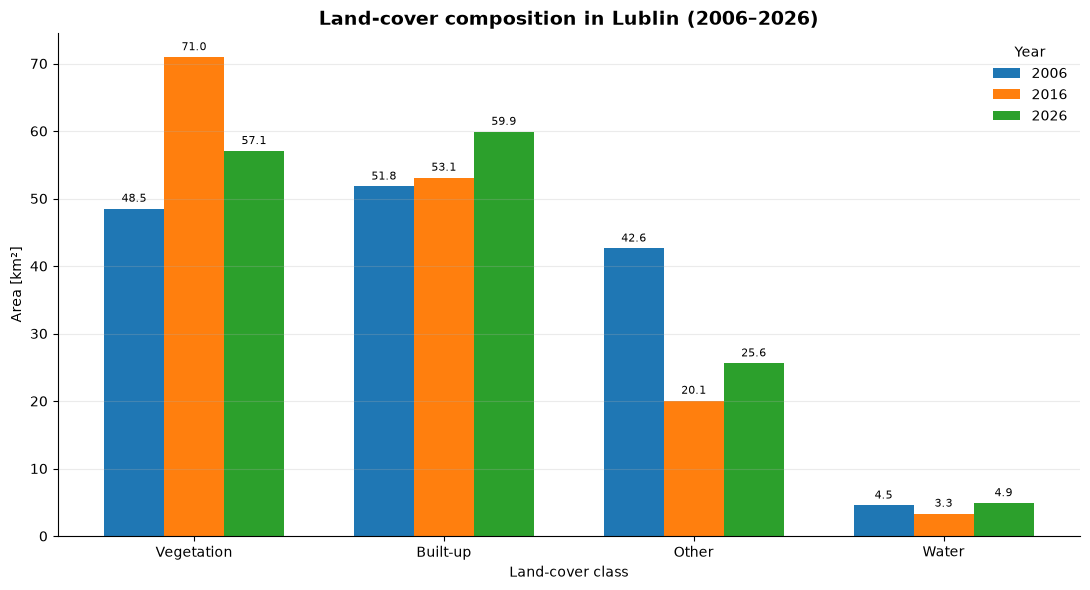

In [29]:
class_labels = [
    "Vegetation",
    "Built-up",
    "Other",
    "Water"
]

years = [2006, 2016, 2026]

x = np.arange(len(class_labels))
width = 0.24

fig, ax = plt.subplots(figsize=(11, 6))

for i, year in enumerate(years):
    values = city_class_pivot[year].values

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=str(year)
    )

    ax.bar_label(
        bars,
        fmt="%.1f",
        padding=3,
        fontsize=8
    )

ax.set_title(
    "Land-cover composition in Lublin (2006–2026)",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Area [km²]")
ax.set_xlabel("Land-cover class")

ax.set_xticks(x)
ax.set_xticklabels(class_labels)

ax.legend(
    title="Year",
    frameon=False
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "land_cover_composition_2006_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Main land-cover change indicators

Newly classified built-up area and vegetation-to-non-vegetation transitions are compared between the three analysed periods.

In [30]:
change_summary_plot = pd.DataFrame({
    "period": ["2006-2016", "2016-2026", "2006-2026"],
    "new_built_up_km2": [11.323698, 15.853144, 19.900786],
    "vegetation_loss_km2": [7.996239, 22.338428, 13.414341]
})

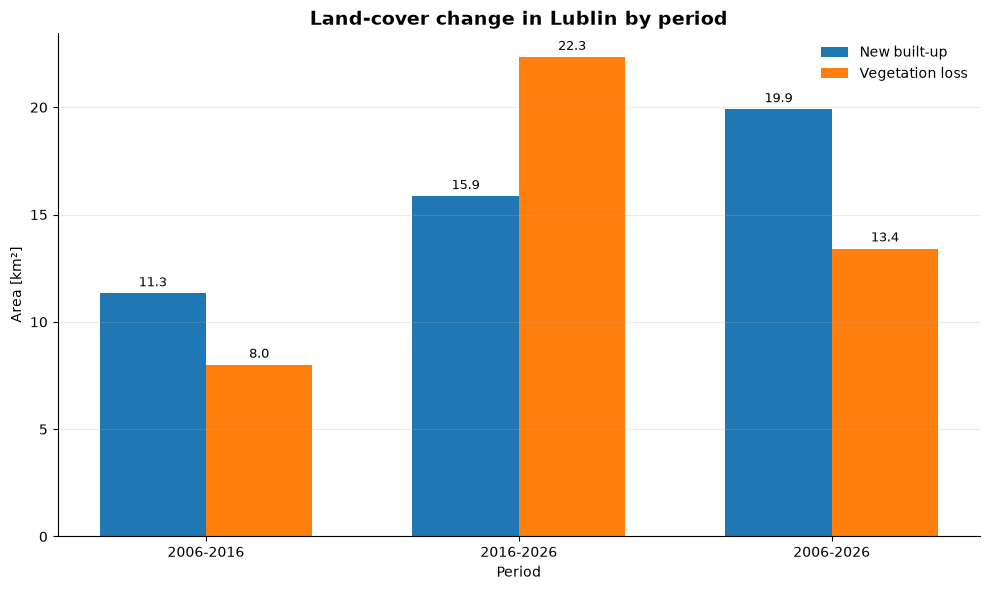

In [31]:
x = np.arange(len(change_summary_plot["period"]))
width = 0.34

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width / 2,
    change_summary_plot["new_built_up_km2"],
    width,
    label="New built-up"
)

bars2 = ax.bar(
    x + width / 2,
    change_summary_plot["vegetation_loss_km2"],
    width,
    label="Vegetation loss"
)

ax.bar_label(
    bars1,
    fmt="%.1f",
    padding=3,
    fontsize=9
)

ax.bar_label(
    bars2,
    fmt="%.1f",
    padding=3,
    fontsize=9
)

ax.set_title(
    "Land-cover change in Lublin by period",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Area [km²]")
ax.set_xlabel("Period")

ax.set_xticks(x)
ax.set_xticklabels(change_summary_plot["period"])

ax.legend(
    frameon=False
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "new_built_up_vs_vegetation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## District-name normalization

A small set of district names contains character-encoding artefacts in the source data. These names are normalized before producing final figures and exported tables.

In [32]:
district_name_fixes = {
    "S?awin": "Sławin",
    "W?glin Pd.": "Węglin Pd.",
    "Czechów P?.": "Czechów Płn.",
    "Hajdów - Zad?bie": "Hajdów - Zadębie",
    "Ko?minek": "Kośminek",
    "G?usk": "Głusk",
    "Dziesi?ta": "Dziesiąta",
    "W?glin P?n.": "Węglin Płn.",
    "Czuby P?n.": "Czuby Płn.",
    "Za Cukrowni?": "Za Cukrownią"
}

for df in [
    district_stats_df,
    district_wide,
    change_2006_2016,
    change_2016_2026,
    change_2006_2026,
    district_change_summary
]:
    df["district"] = df["district"].replace(district_name_fixes)

In [33]:
districts["nazwa"] = districts["nazwa"].replace(district_name_fixes)

## Districts with the largest built-up growth

The ten districts with the largest observed increase in built-up area between 2006 and 2026 are shown.

In [34]:
top_built_up = (
    change_2006_2026[
        ["district", "built_up_change_km2"]
    ]
    .sort_values(
        "built_up_change_km2",
        ascending=True
    )
    .tail(10)
)

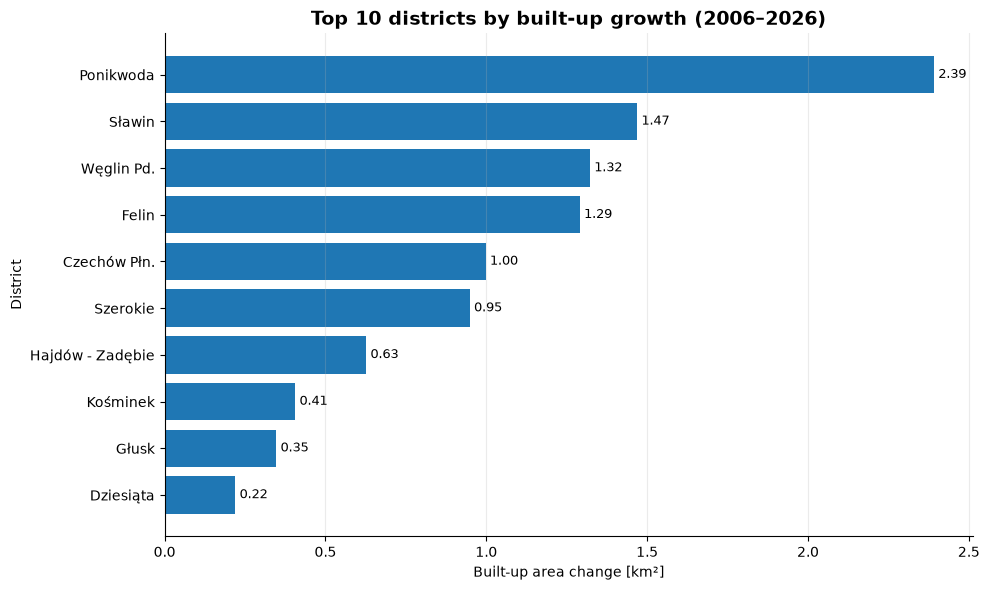

In [35]:
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top_built_up["district"],
    top_built_up["built_up_change_km2"]
)

ax.bar_label(
    bars,
    fmt="%.2f",
    padding=3,
    fontsize=9
)

ax.set_title(
    "Top 10 districts by built-up growth (2006–2026)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Built-up area change [km²]")
ax.set_ylabel("District")

ax.grid(
    axis="x",
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top10_built_up_growth_2006_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Districts with vegetation decline

Only districts with a negative vegetation-area change between 2006 and 2026 are displayed.  
Negative values indicate a smaller area classified as vegetation in 2026 than in 2006.

In [36]:
vegetation_decline = (
    change_2006_2026[
        change_2006_2026["vegetation_change_km2"] < 0
    ][
        ["district", "vegetation_change_km2"]
    ]
    .sort_values("vegetation_change_km2")
)

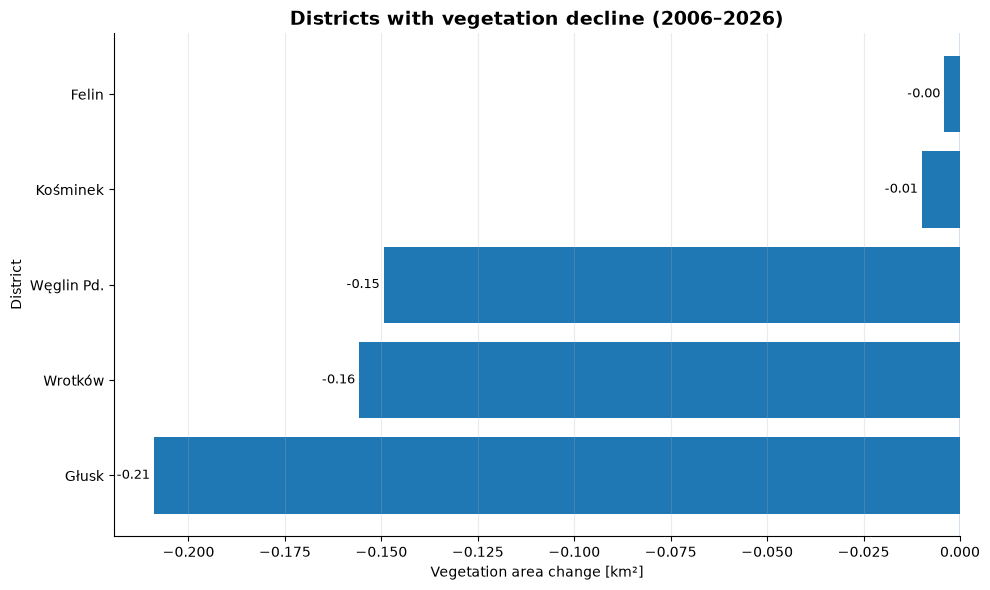

In [37]:
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    vegetation_decline["district"],
    vegetation_decline["vegetation_change_km2"]
)

ax.bar_label(
    bars,
    fmt="%.2f",
    padding=3,
    fontsize=9
)

ax.set_title(
    "Districts with vegetation decline (2006–2026)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Vegetation area change [km²]")
ax.set_ylabel("District")

ax.axvline(0, linewidth=1)

ax.grid(
    axis="x",
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "vegetation_decline_2006_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Spatial pattern of built-up growth

A district-level choropleth map shows the spatial distribution of built-up area change between 2006 and 2026.  
Darker shades represent larger increases in classified built-up area.

In [38]:
district_map = districts.merge(
    change_2006_2026[
        [
            "district",
            "built_up_change_km2",
            "vegetation_change_km2"
        ]
    ],
    left_on="nazwa",
    right_on="district",
    how="left"
)

print(
    district_map[
        [
            "nazwa",
            "built_up_change_km2",
            "vegetation_change_km2"
        ]
    ].head()
)

             nazwa  built_up_change_km2  vegetation_change_km2
0         Wieniawa            -0.302438               0.190619
1         S?awinek            -0.073084               0.037567
2  Kalinowszczyzna            -0.379389               0.575098
3       Węglin Pd.             1.322697              -0.149398
4        Bronowice            -0.367613               0.211424


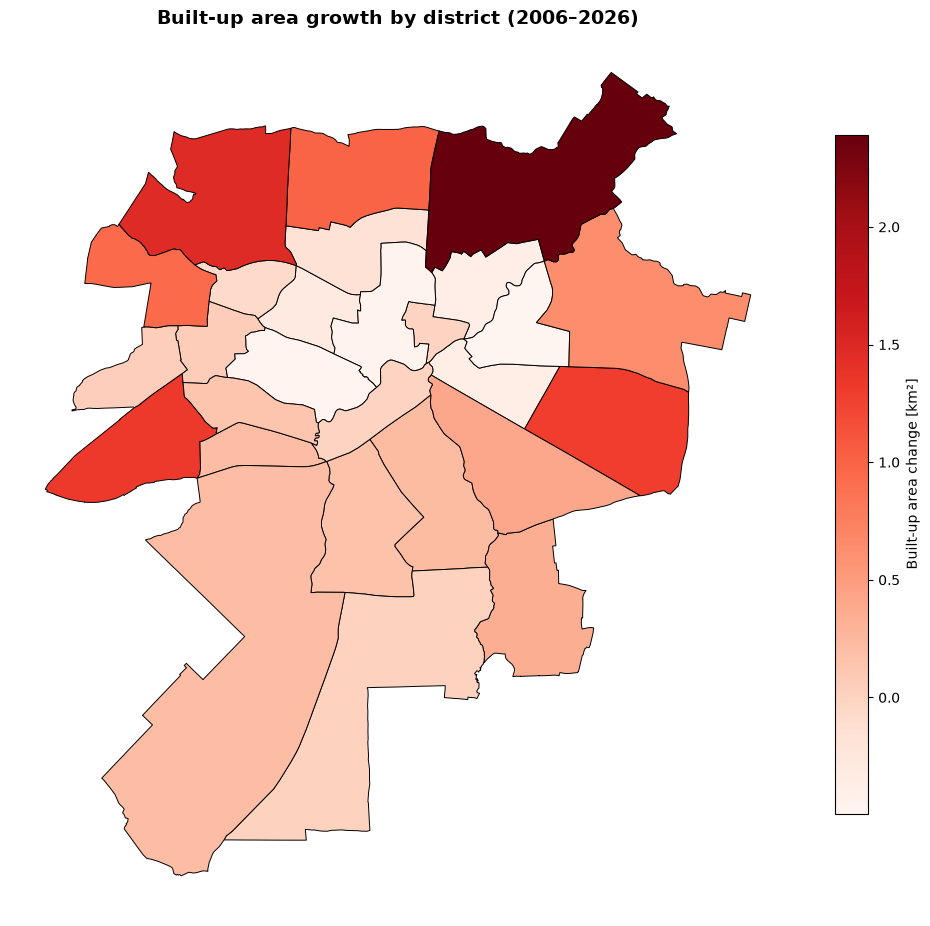

In [39]:
fig, ax = plt.subplots(figsize=(10, 10))

district_map.plot(
    column="built_up_change_km2",
    cmap="Reds",
    linewidth=0.7,
    edgecolor="black",
    legend=True,
    legend_kwds={
        "label": "Built-up area change [km²]",
        "shrink": 0.7
    },
    ax=ax
)

ax.set_title(
    "Built-up area growth by district (2006–2026)",
    fontsize=14,
    fontweight="bold"
)

ax.axis("off")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "district_built_up_growth_2006_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Spatial pattern of vegetation loss

Vegetation loss is mapped only for districts where the vegetation area decreased between 2006 and 2026.   
Darker shades represent a larger decrease in classified vegetation area.

In [40]:
district_map["vegetation_loss_km2"] = (
    -district_map["vegetation_change_km2"]
).clip(lower=0)

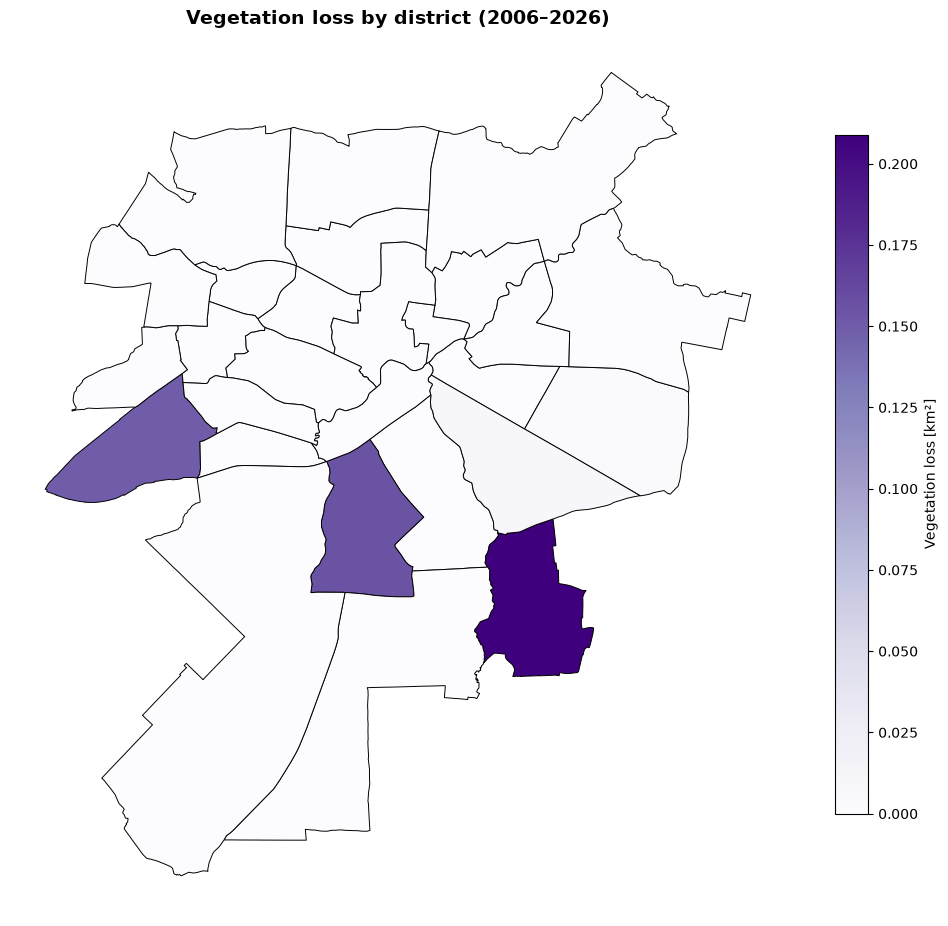

In [41]:
fig, ax = plt.subplots(figsize=(10, 10))

district_map.plot(
    column="vegetation_loss_km2",
    cmap="Purples",
    linewidth=0.7,
    edgecolor="black",
    legend=True,
    legend_kwds={
        "label": "Vegetation loss [km²]",
        "shrink": 0.7
    },
    ax=ax
)

ax.set_title(
    "Vegetation loss by district (2006–2026)",
    fontsize=14,
    fontweight="bold"
)

ax.axis("off")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "district_vegetation_loss_2006_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Built-up growth by decade

Built-up area change in the highest-growth districts is compared between 2006–2016 and 2016–2026.  
This visualization highlights districts where urban expansion remained strong across both decades and districts where the observed rate of change increased or decreased over time.

In [42]:
built_up_decades = (
    change_2006_2016[
        ["district", "built_up_change_km2"]
    ]
    .rename(columns={
        "built_up_change_km2": "2006-2016"
    })
    .merge(
        change_2016_2026[
            ["district", "built_up_change_km2"]
        ].rename(columns={
            "built_up_change_km2": "2016-2026"
        }),
        on="district"
    )
)

built_up_decades["total_change"] = (
    built_up_decades["2006-2016"]
    + built_up_decades["2016-2026"]
)

top_decades = (
    built_up_decades
    .sort_values("total_change", ascending=False)
    .head(10)
    .sort_values("total_change", ascending=True)
)

top_decades

,district,2006-2016,2016-2026,total_change
7,Dziesiąta,-0.086621,0.306696,0.220074
9,Głusk,-0.092186,0.439559,0.347373
12,Kośminek,0.120809,0.285483,0.406293
10,Hajdów - Zadębie,0.273179,0.353658,0.626837
19,Szerokie,0.333979,0.614915,0.948894
3,Czechów Płn.,0.257787,0.740605,0.998392
8,Felin,0.769121,0.521910,1.291031
22,Węglin Pd.,0.697435,0.625263,1.322697
16,Sławin,0.667290,0.802043,1.469333
14,Ponikwoda,1.185521,1.206559,2.392080


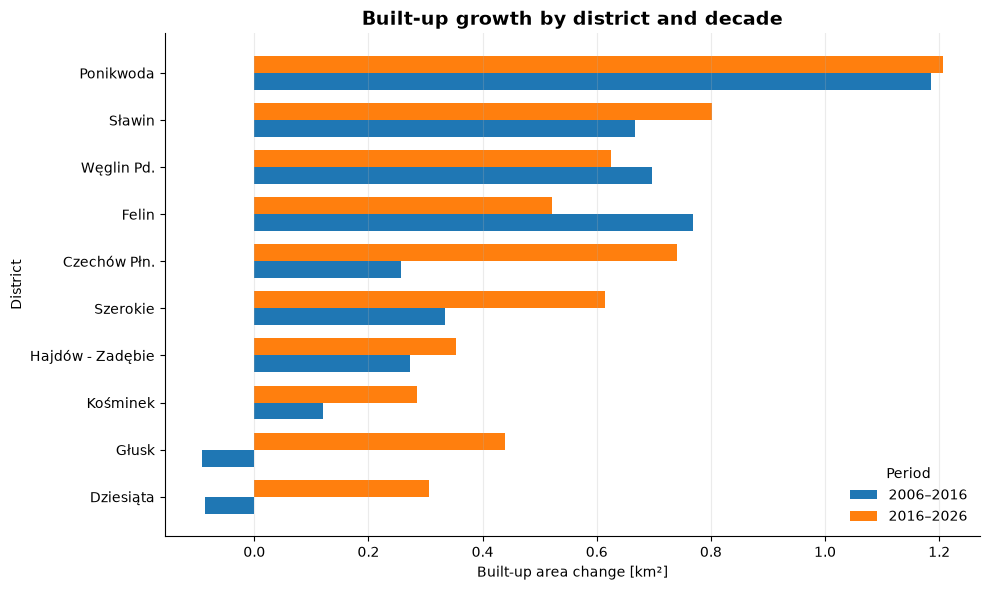

In [43]:
y = np.arange(len(top_decades))
height = 0.36

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.barh(
    y - height / 2,
    top_decades["2006-2016"],
    height,
    label="2006–2016"
)

bars2 = ax.barh(
    y + height / 2,
    top_decades["2016-2026"],
    height,
    label="2016–2026"
)

ax.set_yticks(y)
ax.set_yticklabels(top_decades["district"])

ax.set_title(
    "Built-up growth by district and decade",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Built-up area change [km²]")
ax.set_ylabel("District")

ax.legend(
    title="Period",
    frameon=False
)

ax.grid(
    axis="x",
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "built_up_growth_by_decade.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Export Final Results

The final district statistics, change tables and figures are saved to the `outputs/` directory for use in the project documentation and repository.

In [44]:
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

In [45]:
district_stats_df.to_csv(
    TABLES_DIR / "district_landcover_statistics.csv",
    index=False,
    encoding="utf-8-sig"
)

In [46]:
district_change_summary.to_csv(
    TABLES_DIR / "district_change_2006_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

In [47]:
change_2006_2016.to_csv(
    TABLES_DIR / "district_change_2006_2016.csv",
    index=False,
    encoding="utf-8-sig"
)

change_2016_2026.to_csv(
    TABLES_DIR / "district_change_2016_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

In [48]:
built_up_decades.to_csv(
    TABLES_DIR / "built_up_growth_by_decade.csv",
    index=False,
    encoding="utf-8-sig"
)

In [49]:
print("Figures:")
for path in sorted(FIGURES_DIR.glob("*.png")):
    print("-", path.name)

print("\nTables:")
for path in sorted(TABLES_DIR.glob("*.csv")):
    print("-", path.name)

Figures:
- built_up_growth_by_decade.png
- district_built_up_growth_2006_2026.png
- district_vegetation_loss_2006_2026.png
- land_cover_composition_2006_2026.png
- new_built_up_vs_vegetation_loss.png
- top10_built_up_growth_2006_2026.png
- top10_vegetation_decline_2006_2026.png
- vegetation_decline_2006_2026.png

Tables:
- built_up_growth_by_decade.csv
- district_change_2006_2016.csv
- district_change_2006_2026.csv
- district_change_2016_2026.csv
- district_landcover_statistics.csv


## Summary

The district-level analysis shows that land-cover change in Lublin was spatially uneven.

Built-up growth was concentrated in selected districts rather than distributed uniformly across the city. Ponikwoda showed the largest long-term increase in classified built-up area, while substantial growth was also observed in districts including Sławin, Węglin Południowy and Felin.

The spatial pattern also changed between decades. Some districts showed persistent built-up growth in both periods, while others experienced stronger increases after 2016.

Vegetation change was more heterogeneous. Several districts showed a decrease in classified vegetation area, while others showed stable or increasing values. These results should therefore be interpreted as classified land-cover changes rather than direct measurements of permanent green-space loss.

Together, the city-wide statistics, district-level rankings and choropleth maps provide a spatially explicit summary of urban-growth and vegetation-change patterns in Lublin between 2006 and 2026.